# 16 · Set 5d part 2: hidden signals from one cheap generation (A100, about one session)

Stage A of the hidden-signal plan: **measure whether each signal is informative**. Nothing here routes questions; the informative
signals are saved for stage B (notebook 15), where the planner writes rules over them.

A cheap answerer (Llama 8B, then Llama 3B) answers each of the 200 Set 4 questions **once**, on the same shortlist the cheap fixed
setup uses (Qwen 7B retrieves once). While it does, these are recorded:

| Priority | Signal | What is extracted | Extra inference |
|---|---|---|---|
| 1 | Hidden-state probe | the model's internal activations at the last prompt token (before any answer), over the answer tokens, and on the final answer line; 6 layers | none |
| 2 | Semantic uncertainty probe | a probe trained only to predict whether 5 answers would agree (labels saved in Set 4), then used as a signal | none |
| 3 | Evidence-use attention | share of attention on the passages, the question, and the model's own earlier text | none |
| added | Retriever-side probe | Qwen 7B's hidden state after reading the question and the 20 passages | none |

Passage-perturbation sensitivity (priority "later") is not in this notebook.

**The bar** is the cheap fixed setup: Qwen 7B retrieves once, Qwen 32B answers once (63.5% at 4.2x on these questions). Every score is
on held-out questions, next to the same method run on shuffled labels. PCA and t-SNE maps are drawn, but the held-out number is the evidence.

Extraction uses the `transformers` library directly, because vLLM does not return hidden states or attention. **This notebook is
resumable: if it stops at the time limit, run it again.** My estimate is 45–60 minutes in total (model copies about 18, extraction
about 30, analysis about 5); that is an estimate, not a measurement.

Output: `runs/Set_2__question-reading-routers/<timestamp>_<GPU>_hidden/` with `results/summary.md`, `results/set5d_hidden.xlsx`, `results/charts/`,
`results/signals_for_rules.jsonl`, `results/single_answers_<model>.jsonl`, raw arrays in `step/`.

**Runtime → Change runtime type → A100 GPU.**

In [8]:
# ==== settings ====
PROJECT_DIR = "/content/drive/MyDrive/0_EngD_assignments/0_Small_Big_Model_Switching"
EXPERIMENT  = "Set_2__question-reading-routers"
SWEEP_EXPERIMENT = "Set_1__3-modality-size"     # the finished Set 4 sweep: shortlists, the big answerer's results and the agreement labels come from it
SWEEP_RUN_OVERRIDE = None
ANSWERERS = ["l8", "l3"]              # cheap answerers to probe, in this order
RETRIEVER = "q7"                      # retriever to probe
REPEATS, PERMUTATIONS = 3, 20         # cross-validation repeats and label shuffles in the analysis
TIME_LIMIT_MIN = 55                   # extraction stops cleanly at this limit; run the notebook again to continue
NEW_RUN = False                       # False = continue the latest run of this notebook
DRY_RUN = False                       # True = a tiny random model on CPU, tests the whole notebook in a few minutes

In [9]:
import subprocess, sys, os, json, shutil, time
gpu = subprocess.run("nvidia-smi --query-gpu=name,memory.total,compute_cap --format=csv,noheader 2>/dev/null",
                     shell=True, capture_output=True, text=True).stdout.strip()
print("GPU:", gpu or "none")
if not DRY_RUN:
    assert gpu, "No GPU: Runtime -> Change runtime type -> A100 GPU (or set DRY_RUN = True)."
    if "T4" in gpu:
        raise SystemExit("This runtime has a T4, which cannot run this: the 7B model alone (15 GB) does not fit in its memory.\n"
                         "Runtime -> Change runtime type -> A100 GPU (or G4 / L4) -> Save, then run all cells again.")
    if "A100" not in gpu and "G4" not in gpu and "RTX PRO 6000" not in gpu:
        print("Note: planned for an A100 or G4; this GPU works but timings will differ.")
GPU_TAG = "cpu" if not gpu else gpu.split(",")[0].replace("NVIDIA", "").replace("Tesla", "").strip().split()[0].split("-")[0]
T_START = time.time()

GPU: NVIDIA A100-SXM4-40GB, 40960 MiB, 8.0


In [10]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [11]:
import glob
from datetime import datetime
from zoneinfo import ZoneInfo
SESSION = datetime.now(ZoneInfo("Asia/Singapore")).strftime("%Y%m%d-%H%M%S")
if SWEEP_RUN_OVERRIDE:
    SWEEP_RUN = SWEEP_RUN_OVERRIDE
else:
    done = [d for d in sorted(glob.glob(f"{PROJECT_DIR}/runs/{SWEEP_EXPERIMENT}/*")) if "_dryrun" not in d
            and os.path.exists(f"{d}/sweep_status.json") and json.load(open(f"{d}/sweep_status.json")).get("complete")
            and os.path.exists(f"{d}/results/per_question.jsonl")]
    assert done, f"No complete sweep found in runs/{SWEEP_EXPERIMENT} - finish notebook 11 first."
    SWEEP_RUN = done[-1]
DATA_DIR = json.load(open(f"{SWEEP_RUN}/config.json"))["data_dir"]
tag = "_hidden_dryrun" if DRY_RUN else "_hidden"
prev = sorted(d for d in glob.glob(f"{PROJECT_DIR}/runs/{EXPERIMENT}/*{tag}"))
RUN_DIR = prev[-1] if (prev and not NEW_RUN) else f"{PROJECT_DIR}/runs/{EXPERIMENT}/{SESSION}_{GPU_TAG}{tag}"
SESSION_DIR = f"{RUN_DIR}/sessions/{SESSION}_hidden"
for d in (f"{RUN_DIR}/code", f"{RUN_DIR}/logs", f"{RUN_DIR}/step", f"{RUN_DIR}/stages", SESSION_DIR):
    os.makedirs(d, exist_ok=True)
CODE_DIR = "/content/set5code"
os.makedirs(CODE_DIR, exist_ok=True)
for f in ("ssw.py", "sweep.py", "routers.py", "structure.py", "hidden.py"):
    shutil.copy(f"{PROJECT_DIR}/code/{f}", f"{CODE_DIR}/{f}")
    shutil.copy(f"{PROJECT_DIR}/code/{f}", f"{RUN_DIR}/code/{f}")       # keep the exact code with the results
TIMES = {}
print("Set 4 sweep used:", SWEEP_RUN)
print("Run folder:", RUN_DIR)

Set 4 sweep used: /content/drive/MyDrive/0_EngD_assignments/0_Small_Big_Model_Switching/runs/Set_1__3-modality-size/20261004-165402_A100
Run folder: /content/drive/MyDrive/0_EngD_assignments/0_Small_Big_Model_Switching/runs/Set_2__question-reading-routers/20261007-075955_A100_hidden


In [12]:
MODELS = {   # key: model, folder under models/, parameters (for compute), nominal size (for the AgentTTS budget formula)
    "q3":  {"id": "Qwen/Qwen2.5-3B-Instruct",        "dir": "Qwen2.5-3B-Instruct",        "params": 3.09e9,  "nominal": 3e9},
    "q7":  {"id": "Qwen/Qwen2.5-7B-Instruct",        "dir": "Qwen2.5-7B-Instruct",        "params": 7.62e9,  "nominal": 7e9},
    "q32": {"id": "Qwen/Qwen2.5-32B-Instruct-AWQ",   "dir": "Qwen2.5-32B-Instruct-AWQ",   "params": 32.76e9, "nominal": 32e9},
    "l3":  {"id": "meta-llama/Llama-3.2-3B-Instruct", "dir": "Llama-3.2-3B-Instruct",     "params": 3.21e9,  "nominal": 3e9},
    "l8":  {"id": "meta-llama/Llama-3.1-8B-Instruct", "dir": "Llama-3.1-8B-Instruct",     "params": 8.03e9,  "nominal": 8e9},
}
LOCAL = "/content/models"
for m in MODELS.values():
    m["path"] = f"{LOCAL}/{m['dir']}"

def ensure_local(key):
    """Copies one model from Drive to the runtime's local disk (only when a stage needs it)."""
    m = MODELS[key]
    src = f"{PROJECT_DIR}/models/{m['dir']}"
    if DRY_RUN or os.path.exists(f"{m['path']}/config.json"):
        return
    assert os.path.exists(f"{src}/config.json"), f"{src} missing - run notebook 10 first."
    idx = f"{src}/model.safetensors.index.json"
    if os.path.exists(idx):
        lost = [f for f in sorted(set(json.load(open(idx))["weight_map"].values())) if not os.path.exists(f"{src}/{f}")]
        assert not lost, f"{src} is incomplete (missing {lost}) - run notebook 10 again."
    t = time.time()
    print(f"copying {m['dir']} to local disk ...")
    shutil.copytree(src, m["path"], dirs_exist_ok=True)
    TIMES[f"copy_{key}"] = round(time.time() - t)
json.dump(MODELS, open(f"{RUN_DIR}/models.json", "w"), indent=1)
json.dump({"experiment": EXPERIMENT, "set": "5d part 2", "sweep_run": SWEEP_RUN, "data_dir": DATA_DIR, "answerers": ANSWERERS, "retriever": RETRIEVER,
           "gpu": gpu, "dry_run": DRY_RUN, "started": SESSION}, open(f"{RUN_DIR}/config.json", "w"), indent=1)

def minutes_left():
    return max(0.0, TIME_LIMIT_MIN - (time.time() - T_START) / 60)

def run_stage(args, log_name):
    cmd = [sys.executable, "-u", f"{CODE_DIR}/hidden.py"] + [str(a) for a in args]
    t0 = time.time()
    with open(f"{RUN_DIR}/logs/{log_name}", "a") as log, open(f"{SESSION_DIR}/{log_name}", "a") as slog:
        p = subprocess.Popen(cmd, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, bufsize=1)
        for line in p.stdout:
            log.write(line); slog.write(line)
            if not any(k in line for k in ("it/s]", "s/it]", "Loading checkpoint")):
                print(line, end="")
        p.wait()
    TIMES[log_name.replace(".log", "")] = TIMES.get(log_name.replace(".log", ""), 0) + round(time.time() - t0)
    json.dump(TIMES, open(f"{SESSION_DIR}/stage_times.json", "w"), indent=1)
    assert p.returncode == 0, f"stage failed - see {RUN_DIR}/logs/{log_name}"

COMMON = ["--sweep_run", SWEEP_RUN, "--data_dir", DATA_DIR, "--run_dir", RUN_DIR, "--models_json", f"{RUN_DIR}/models.json"]
N_QUESTIONS = sum(len(json.load(open(f"{DATA_DIR}/{s}.json", encoding="utf-8"))) for s in ("dev", "test"))

def stage_done(role, key):
    p = f"{RUN_DIR}/step/hidden_{role}_{key}.jsonl"
    return os.path.exists(p) and sum(1 for _ in open(p, encoding="utf-8")) >= N_QUESTIONS

### Extract the signals (resumable)

In [13]:
STAGES = [("answer", k) for k in ANSWERERS] + [("retrieve", RETRIEVER)]
extra = ["--backend", "tiny", "--max_new", 30] if DRY_RUN else []
for role, key in STAGES:
    if stage_done(role, key):
        print(f"{role} {key}: already complete")
        continue
    if minutes_left() < 6:
        print(f"Time limit close ({minutes_left():.0f} min left) - {role} {key} not started. Run this notebook again to continue.")
        break
    ensure_local(key)
    run_stage(["extract", "--model", key, "--role", role, "--time_limit_min", max(1.0, minutes_left() - 4)] + COMMON + extra, f"extract_{role}_{key}.log")
ALL_DONE = all(stage_done(r, k) for r, k in STAGES)
print("\nExtraction complete." if ALL_DONE else "\nEXTRACTION NOT COMPLETE YET - the analysis below uses what is finished; run this notebook again to continue.")

answer l8: already complete
[03:20:29] extract answer l3: 33 done, 167 to do
[transformers] `torch_dtype` is deprecated! Use `dtype` instead!

[03:20:38] model ready in 9s on cuda:0
[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer TokenizersBackend. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.
[03:23:02]   answer l3: 53/200 (7.2s per question)
[03:25:29]   answer l3: 73/200 (7.3s per question)
[03:27:52]   answer l3: 93/200 (7.2s per question)
[03:30:19]   answer l3: 113/200 (7.3s per question)
[03:33:01]   answer l3: 133/200 (7.4s per question)
[03:35:35]   answer l3: 153/200 (7.5s per question)
[03:37:47]   answer l3: 173/200 (7.4s per question)
[03:40:09]   answer l3: 193/200 (7.3s 

### Analyse: probes, shuffled-label controls, layer by layer, and what each signal would buy

[03:48:58] reading /content/drive/MyDrive/0_EngD_assignments/0_Small_Big_Model_Switching/runs/Set_1__3-modality-size/20261004-165402_A100/results/per_question.jsonl ...
[03:49:04] 200 questions (100 dev, 100 test), 648 setups
[03:50:02]   Llama 8B: hidden state at the last prompt token, before answering done
[03:50:58]   Llama 8B: hidden state averaged over the answer tokens done
[03:51:54]   Llama 8B: hidden state on the final answer line done
[03:53:55]   Llama 8B: tables done
[03:54:50]   Llama 3B: hidden state at the last prompt token, before answering done
[03:55:45]   Llama 3B: hidden state averaged over the answer tokens done
[03:56:42]   Llama 3B: hidden state on the final answer line done
[03:58:43]   Llama 3B: tables done
[03:59:33]   retriever done
[03:59:50] done in 653s -> /content/drive/MyDrive/0_EngD_assignments/0_Small_Big_Model_Switching/runs/Set_2__question-reading-routers/20261007-075955_A100_hidden/results


# Set 5d part 2 - hidden signals from one cheap generation

Sweep used: `20261004-165402_A100`. Shortlist: Qwen 7B retrieves once (CoT, per-attempt shortlist 3), as in the cheap fixed setup. The cheap answerer answers once, greedily. The bar is the cheap fixed setup (Qwen 7B retrieves once, Qwen 32B answers once): **63.5% at 4.2x**.
Every separation is on held-out questions (5-fold cross-validation x3); 0.5 = useless. 'Beats shuffled labels' = above the 95th percentile of the same method on 20 label shuffles. 250 of 613 combinations beat shuffled labels; chance alone would give about 31.
This is stage A (is each signal informative?). The informative signals are saved in `results/signals_for_rules.jsonl` for stage B, where the planner writes rules over them.

## 1. The single cheap answers

| Answerer | Questions | Accuracy | Set 4 accuracy, 1 answer (sampled, with fusion) | Set 4 accuracy, 5 answers + fusion | Big answerer on the same questions | Mean answer tokens | Answers cut off at the length cap | Attention measured |
|---|---|---|---|---|---|---|---|---|
| Llama 8B | 200 | 54.0% | 53.0% | 53.0% | 63.5% | 248.33 | 7.5% | 100.0% |
| Llama 3B | 200 | 44.0% | 39.0% | 46.5% | 63.5% | 177.47 | 1.5% | 100.0% |

## 2. Which signals predict the routing target? (best layer and reading of each signal)

Picking the best layer after the fact flatters the hidden-state rows a little; section 5 shows every layer.

| Signal | How it is read | Separation on held-out questions (0.5 = useless) | Same method with shuffled labels: 95th percentile | Beats shuffled labels | Extra cost of having this signal |
|---|---|---|---|---|---|
| Llama 3B: its single answer equals Llama 8B's single answer | linear probe | 0.74 | 0.53 | True | one single answer from Llama 8B as well |
| Llama 8B: evidence-use attention signals | first 2 principal components (PCA) | 0.72 | 0.56 | True | none beyond one cheap answer |
| Llama 8B: hidden state on the final answer line | linear probe | 0.68 | 0.63 | True | none beyond one cheap answer |
| Llama 8B: all single-generation signals together | first 2 principal components (PCA) | 0.68 | 0.57 | True | none beyond one cheap answer |
| Llama 8B: token probabilities of the single answer | boosted trees | 0.66 | 0.57 | True | none beyond one cheap answer |
| Llama 8B: hidden state averaged over the answer tokens | linear probe | 0.65 | 0.64 | True | none beyond one cheap answer |
| Llama 8B: hidden state at the last prompt token, before answering | semantic uncertainty probe (trained only to predict whether 5 answers agree) | 0.65 | 0.56 | True | none: read before the cheap answer is written |
| Llama 3B: hidden state on the final answer line | nearest neighbours (t-SNE-style neighbourhoods) | 0.64 | 0.57 | True | none beyond one cheap answer |
| Llama 8B: agreement of 5 answers (the Set 4 signal, for comparison) | linear probe | 0.62 | 0.57 | True | four more cheap answers: about 1.0x |
| Llama 8B: its single answer equals Llama 3B's single answer | linear probe | 0.62 | 0.53 | True | one single answer from Llama 3B as well |
| Llama 3B: agreement of 5 answers (the Set 4 signal, for comparison) | nearest neighbours (t-SNE-style neighbourhoods) | 0.61 | 0.54 | True | four more cheap answers: about 1.0x |
| Llama 3B: hidden state averaged over the answer tokens | nearest neighbours (t-SNE-style neighbourhoods) | 0.60 | 0.55 | True | none beyond one cheap answer |
| Llama 3B: hidden state at the last prompt token, before answering | linear probe | 0.59 | 0.54 | True | none: read before the cheap answer is written |
| Llama 3B: evidence-use attention signals | linear probe | 0.56 | 0.60 | False | none beyond one cheap answer |
| Llama 3B: all single-generation signals together | first 2 principal components (PCA) | 0.55 | 0.56 | False | none beyond one cheap answer |
| Llama 3B: token probabilities of the single answer | nearest neighbours (t-SNE-style neighbourhoods) | 0.54 | 0.58 | False | none beyond one cheap answer |
| Llama 8B: stated confidence of the single answer | nearest neighbours (t-SNE-style neighbourhoods) | 0.52 | 0.54 | False | none beyond one cheap answer |
| Llama 3B: stated confidence of the single answer | nearest neighbours (t-SNE-style neighbourhoods) | 0.48 | 0.53 | False | none beyond one cheap answer |

## 3. Semantic uncertainty: can one generation's hidden states predict whether 5 answers would agree?

| Signal | How it is read | Separation on held-out questions (0.5 = useless) | Same method with shuffled labels: 95th percentile | Beats shuffled labels | Extra cost of having this signal |
|---|---|---|---|---|---|
| Llama 8B: agreement of 5 answers (the Set 4 signal, for comparison) | linear probe | 1.00 | 0.53 | True | four more cheap answers: about 1.0x |
| Llama 3B: agreement of 5 answers (the Set 4 signal, for comparison) | linear probe | 1.00 | 0.59 | True | four more cheap answers: about 1.0x |
| Llama 8B: all single-generation signals together | first 2 principal components (PCA) | 0.71 | 0.58 | True | none beyond one cheap answer |
| Llama 8B: token probabilities of the single answer | first 2 principal components (PCA) | 0.70 | 0.54 | True | none beyond one cheap answer |
| Llama 8B: evidence-use attention signals | first 2 principal components (PCA) | 0.69 | 0.59 | True | none beyond one cheap answer |
| Llama 3B: token probabilities of the single answer | first 2 principal components (PCA) | 0.66 | 0.59 | True | none beyond one cheap answer |
| Llama 3B: all single-generation signals together | linear probe | 0.64 | 0.60 | True | none beyond one cheap answer |
| Llama 3B: evidence-use attention signals | nearest neighbours (t-SNE-style neighbourhoods) | 0.63 | 0.57 | True | none beyond one cheap answer |
| Llama 8B: hidden state averaged over the answer tokens | linear probe | 0.62 | 0.55 | True | none beyond one cheap answer |
| Llama 3B: hidden state on the final answer line | linear probe | 0.62 | 0.57 | True | none beyond one cheap answer |
| Llama 3B: hidden state at the last prompt token, before answering | linear probe | 0.62 | 0.59 | True | none: read before the cheap answer is written |
| Llama 8B: hidden state on the final answer line | linear probe | 0.62 | 0.55 | True | none beyond one cheap answer |
| Llama 8B: hidden state at the last prompt token, before answering | linear probe | 0.60 | 0.59 | True | none: read before the cheap answer is written |
| Llama 3B: hidden state averaged over the answer tokens | nearest neighbours (t-SNE-style neighbourhoods) | 0.59 | 0.54 | True | none beyond one cheap answer |
| Llama 8B: stated confidence of the single answer | nearest neighbours (t-SNE-style neighbourhoods) | 0.58 | 0.55 | True | none beyond one cheap answer |
| Llama 3B: stated confidence of the single answer | nearest neighbours (t-SNE-style neighbourhoods) | 0.50 | 0.52 | False | none beyond one cheap answer |

## 4. What a signal would buy as a gate in front of the big answerer

The gate escalates the questions the signal is least sure about. For signals read before answering, an escalated question skips the cheap answer.

| Answerer | Gate | Share escalated | Accuracy | Compute (x cheapest) | Accuracy vs the cheap fixed setup (points) | Compute vs the cheap fixed setup | Accuracy of a random gate with the same share |
|---|---|---|---|---|---|---|---|
| Llama 3B | always the cheap answerer, one answer | 0.0% | 44.0% | 1.8x | -19.50 | -57.3% | - |
| Llama 3B | always the big answerer = the cheap fixed setup | 100.0% | 63.5% | 4.2x | 0.00 | 0.0% | - |
| Llama 3B | Llama 3B: its single answer equals Llama 8B's single answer | linear probe | 35.5% | 57.5% | 3.2x | -6.00 | -24.1% | 50.9% |
| Llama 3B | Llama 3B: its single answer equals Llama 8B's single answer | linear probe | 51.5% | 62.5% | 3.6x | -1.00 | -14.4% | 54.0% |
| Llama 3B | Llama 3B: hidden state on the final answer line | nearest neighbours (t-SNE-style neighbourhoods) | 41.5% | 56.5% | 2.9x | -7.00 | -31.6% | 52.1% |
| Llama 3B | Llama 3B: hidden state on the final answer line | nearest neighbours (t-SNE-style neighbourhoods) | 51.0% | 58.5% | 3.1x | -5.00 | -25.8% | 53.9% |
| Llama 3B | Llama 3B: agreement of 5 answers (the Set 4 signal, for comparison) | nearest neighbours (t-SNE-style neighbourhoods) | 36.0% | 54.5% | 3.4x | -9.00 | -19.3% | 51.0% |
| Llama 3B | Llama 3B: agreement of 5 answers (the Set 4 signal, for comparison) | nearest neighbours (t-SNE-style neighbourhoods) | 55.0% | 58.5% | 3.9x | -5.00 | -7.4% | 54.7% |
| Llama 3B | Llama 3B: hidden state averaged over the answer tokens | nearest neighbours (t-SNE-style neighbourhoods) | 35.0% | 51.0% | 2.7x | -12.50 | -35.6% | 50.8% |
| Llama 3B | Llama 3B: hidden state averaged over the answer tokens | nearest neighbours (t-SNE-style neighbourhoods) | 52.5% | 56.5% | 3.1x | -7.00 | -25.0% | 54.2% |
| Llama 3B | Llama 3B: hidden state at the last prompt token, before answering | linear probe | 35.0% | 55.0% | 2.7x | -8.50 | -35.9% | 50.8% |
| Llama 3B | Llama 3B: hidden state at the last prompt token, before answering | linear probe | 50.0% | 57.5% | 3.1x | -6.00 | -26.8% | 53.8% |
| Llama 3B | Llama 3B: evidence-use attention signals | linear probe | 35.0% | 53.5% | 2.7x | -10.00 | -35.8% | 50.8% |
| Llama 3B | Llama 3B: evidence-use attention signals | linear probe | 50.0% | 56.0% | 3.1x | -7.50 | -26.5% | 53.8% |
| Llama 3B | Llama 3B: all single-generation signals together | first 2 principal components (PCA) | 35.0% | 52.0% | 2.7x | -11.50 | -35.9% | 50.8% |
| Llama 3B | Llama 3B: all single-generation signals together | first 2 principal components (PCA) | 50.0% | 56.0% | 3.1x | -7.50 | -26.8% | 53.8% |
| Llama 3B | Llama 3B: token probabilities of the single answer | nearest neighbours (t-SNE-style neighbourhoods) | 42.5% | 52.5% | 2.9x | -11.00 | -31.2% | 52.3% |
| Llama 3B | Llama 3B: token probabilities of the single answer | nearest neighbours (t-SNE-style neighbourhoods) | 53.5% | 53.5% | 3.2x | -10.00 | -24.5% | 54.4% |
| Llama 3B | Llama 3B: stated confidence of the single answer | nearest neighbours (t-SNE-style neighbourhoods) | 41.0% | 53.0% | 2.8x | -10.50 | -32.1% | 52.0% |
| Llama 8B | always the cheap answerer, one answer | 0.0% | 54.0% | 2.1x | -9.50 | -50.5% | - |
| Llama 8B | always the big answerer = the cheap fixed setup | 100.0% | 63.5% | 4.2x | 0.00 | 0.0% | - |
| Llama 8B | Llama 8B: evidence-use attention signals | first 2 principal components (PCA) | 35.0% | 61.5% | 3.0x | -2.00 | -27.6% | 57.3% |
| Llama 8B | Llama 8B: evidence-use attention signals | first 2 principal components (PCA) | 50.0% | 62.0% | 3.4x | -1.50 | -18.6% | 58.8% |
| Llama 8B | Llama 8B: hidden state on the final answer line | linear probe | 35.0% | 60.0% | 3.0x | -3.50 | -28.5% | 57.3% |
| Llama 8B | Llama 8B: hidden state on the final answer line | linear probe | 50.0% | 60.0% | 3.4x | -3.50 | -19.6% | 58.8% |
| Llama 8B | Llama 8B: all single-generation signals together | first 2 principal components (PCA) | 35.0% | 60.5% | 3.0x | -3.00 | -27.7% | 57.3% |
| Llama 8B | Llama 8B: all single-generation signals together | first 2 principal components (PCA) | 50.0% | 61.0% | 3.4x | -2.50 | -18.5% | 58.8% |
| Llama 8B | Llama 8B: token probabilities of the single answer | boosted trees | 35.0% | 59.0% | 3.0x | -4.50 | -28.1% | 57.3% |
| Llama 8B | Llama 8B: token probabilities of the single answer | boosted trees | 50.0% | 61.5% | 3.4x | -2.00 | -19.0% | 58.8% |
| Llama 8B | Llama 8B: hidden state averaged over the answer tokens | linear probe | 35.0% | 58.5% | 3.0x | -5.00 | -29.1% | 57.3% |
| Llama 8B | Llama 8B: hidden state averaged over the answer tokens | linear probe | 50.0% | 60.5% | 3.4x | -3.00 | -19.9% | 58.8% |
| Llama 8B | Llama 8B: hidden state at the last prompt token, before answering | semantic uncertainty probe (trained only to predict whether 5 answers agree) | 35.0% | 59.5% | 2.9x | -4.00 | -29.8% | 57.3% |
| Llama 8B | Llama 8B: hidden state at the last prompt token, before answering | semantic uncertainty probe (trained only to predict whether 5 answers agree) | 50.0% | 62.5% | 3.3x | -1.00 | -21.3% | 58.8% |
| Llama 8B | Llama 8B: agreement of 5 answers (the Set 4 signal, for comparison) | linear probe | 35.0% | 61.0% | 4.8x | -2.50 | 14.4% | 57.3% |
| Llama 8B | Llama 8B: agreement of 5 answers (the Set 4 signal, for comparison) | linear probe | 50.0% | 61.5% | 5.2x | -2.00 | 23.4% | 58.8% |
| Llama 8B | Llama 8B: its single answer equals Llama 3B's single answer | linear probe | 35.0% | 59.0% | 3.2x | -4.50 | -24.7% | 57.3% |
| Llama 8B | Llama 8B: its single answer equals Llama 3B's single answer | linear probe | 50.0% | 62.5% | 3.6x | -1.00 | -15.4% | 58.8% |
| Llama 8B | Llama 8B: stated confidence of the single answer | nearest neighbours (t-SNE-style neighbourhoods) | 58.0% | 59.5% | 3.6x | -4.00 | -14.8% | 59.5% |

**Any point within 2 points of the cheap fixed setup at 15% or more less compute?** Yes, 18 points on the curves (in-sample over the escalation share, so provisional): Llama 3B: its single answer equals Llama 8B's single answer | linear probe [Llama 3B]; Llama 8B: all single-generation signals together | first 2 principal components (PCA) [Llama 8B]; Llama 8B: evidence-use attention signals | first 2 principal components (PCA) [Llama 8B]; Llama 8B: hidden state at the last prompt token, before answering | semantic uncertainty probe (trained only to predict whether 5 answers agree) [Llama 8B]; Llama 8B: its single answer equals Llama 3B's single answer | linear probe [Llama 8B]; Llama 8B: token probabilities of the single answer | boosted trees [Llama 8B].

## 5. Layer by layer (linear probe, routing target)

| Model | Where | Layer | Depth (share of layers) | Separation on held-out questions (0.5 = useless) | Beats shuffled labels |
|---|---|---|---|---|---|
| Llama 8B | hidden state at the last prompt token, before answering | 8 | 0.25 | 0.45 | False |
| Llama 8B | hidden state at the last prompt token, before answering | 16 | 0.50 | 0.51 | False |
| Llama 8B | hidden state at the last prompt token, before answering | 20 | 0.62 | 0.47 | False |
| Llama 8B | hidden state at the last prompt token, before answering | 24 | 0.75 | 0.46 | False |
| Llama 8B | hidden state at the last prompt token, before answering | 28 | 0.88 | 0.45 | False |
| Llama 8B | hidden state at the last prompt token, before answering | 32 | 1.00 | 0.52 | False |
| Llama 8B | hidden state averaged over the answer tokens | 8 | 0.25 | 0.61 | True |
| Llama 8B | hidden state averaged over the answer tokens | 16 | 0.50 | 0.57 | False |
| Llama 8B | hidden state averaged over the answer tokens | 20 | 0.62 | 0.65 | True |
| Llama 8B | hidden state averaged over the answer tokens | 24 | 0.75 | 0.62 | True |
| Llama 8B | hidden state averaged over the answer tokens | 28 | 0.88 | 0.65 | True |
| Llama 8B | hidden state averaged over the answer tokens | 32 | 1.00 | 0.59 | True |
| Llama 8B | hidden state on the final answer line | 8 | 0.25 | 0.66 | True |
| Llama 8B | hidden state on the final answer line | 16 | 0.50 | 0.61 | True |
| Llama 8B | hidden state on the final answer line | 20 | 0.62 | 0.59 | True |
| Llama 8B | hidden state on the final answer line | 24 | 0.75 | 0.65 | True |
| Llama 8B | hidden state on the final answer line | 28 | 0.88 | 0.68 | True |
| Llama 8B | hidden state on the final answer line | 32 | 1.00 | 0.59 | True |
| Llama 3B | hidden state at the last prompt token, before answering | 7 | 0.25 | 0.59 | True |
| Llama 3B | hidden state at the last prompt token, before answering | 14 | 0.50 | 0.42 | False |
| Llama 3B | hidden state at the last prompt token, before answering | 18 | 0.64 | 0.50 | False |
| Llama 3B | hidden state at the last prompt token, before answering | 21 | 0.75 | 0.50 | False |
| Llama 3B | hidden state at the last prompt token, before answering | 24 | 0.86 | 0.50 | False |
| Llama 3B | hidden state at the last prompt token, before answering | 28 | 1.00 | 0.46 | False |
| Llama 3B | hidden state averaged over the answer tokens | 7 | 0.25 | 0.55 | False |
| Llama 3B | hidden state averaged over the answer tokens | 14 | 0.50 | 0.54 | False |
| Llama 3B | hidden state averaged over the answer tokens | 18 | 0.64 | 0.55 | False |
| Llama 3B | hidden state averaged over the answer tokens | 21 | 0.75 | 0.50 | False |
| Llama 3B | hidden state averaged over the answer tokens | 24 | 0.86 | 0.48 | False |
| Llama 3B | hidden state averaged over the answer tokens | 28 | 1.00 | 0.56 | False |
| Llama 3B | hidden state on the final answer line | 7 | 0.25 | 0.60 | True |
| Llama 3B | hidden state on the final answer line | 14 | 0.50 | 0.59 | False |
| Llama 3B | hidden state on the final answer line | 18 | 0.64 | 0.56 | False |
| Llama 3B | hidden state on the final answer line | 21 | 0.75 | 0.61 | True |
| Llama 3B | hidden state on the final answer line | 24 | 0.86 | 0.59 | True |
| Llama 3B | hidden state on the final answer line | 28 | 1.00 | 0.58 | True |

## 6. Retriever-side probe

| Signal | How it is read | Separation on held-out questions (0.5 = useless) | Same method with shuffled labels: 95th percentile | Beats shuffled labels | Extra cost of having this signal | What is predicted |
|---|---|---|---|---|---|---|
| Qwen 7B (retriever): agreement of its 3 tries (the Set 4 signal, for comparison) | linear probe | 0.77 | 0.55 | True | two more retrieval tries: about 2.2x | a bigger retriever is needed (Qwen 32B finds both, this one does not) |
| Qwen 7B (retriever): hidden state after reading the question and 20 passages | linear probe | 0.77 | 0.59 | True | none: part of the retrieval pass | a bigger retriever is needed (Qwen 32B finds both, this one does not) |
| Qwen 7B (retriever): hidden state after reading the question and 20 passages | linear probe | 0.73 | 0.73 | True | none: part of the retrieval pass | Qwen 7B finds both passages in 3 tries (keep all) |
| Qwen 7B (retriever): agreement of its 3 tries (the Set 4 signal, for comparison) | linear probe | 0.70 | 0.57 | True | two more retrieval tries: about 2.2x | Qwen 7B finds both passages in 1 try |
| Qwen 7B (retriever): hidden state after reading the question and 20 passages | linear probe | 0.65 | 0.59 | True | none: part of the retrieval pass | Qwen 7B finds both passages in 1 try |
| Qwen 7B (retriever): agreement of its 3 tries (the Set 4 signal, for comparison) | linear probe | 0.29 | 0.58 | False | two more retrieval tries: about 2.2x | Qwen 7B finds both passages in 3 tries (keep all) |

## 7. Top 20 combinations overall

| What is looked at | How it is read | What is predicted | Separation on held-out questions (0.5 = useless) | Same method with shuffled labels: 95th percentile | Beats shuffled labels |
|---|---|---|---|---|---|
| Llama 8B: agreement of 5 answers (the Set 4 signal, for comparison) | linear probe | Llama 8B's 5 answers all agree | 1.00 | 0.53 | True |
| Llama 8B: agreement of 5 answers (the Set 4 signal, for comparison) | nearest neighbours (t-SNE-style neighbourhoods) | Llama 8B's 5 answers all agree | 1.00 | 0.56 | True |
| Llama 8B: agreement of 5 answers (the Set 4 signal, for comparison) | boosted trees | Llama 8B's 5 answers all agree | 1.00 | 0.59 | True |
| Llama 3B: agreement of 5 answers (the Set 4 signal, for comparison) | linear probe | Llama 3B's 5 answers all agree | 1.00 | 0.59 | True |
| Llama 3B: agreement of 5 answers (the Set 4 signal, for comparison) | first 2 principal components (PCA) | Llama 3B's 5 answers all agree | 1.00 | 0.55 | True |
| Llama 3B: agreement of 5 answers (the Set 4 signal, for comparison) | nearest neighbours (t-SNE-style neighbourhoods) | Llama 3B's 5 answers all agree | 1.00 | 0.56 | True |
| Llama 3B: agreement of 5 answers (the Set 4 signal, for comparison) | boosted trees | Llama 3B's 5 answers all agree | 1.00 | 0.60 | True |
| Llama 8B: agreement of 5 answers (the Set 4 signal, for comparison) | first 2 principal components (PCA) | Llama 8B's 5 answers all agree | 1.00 | 0.53 | True |
| Qwen 7B (retriever): agreement of its 3 tries (the Set 4 signal, for comparison) | linear probe | a bigger retriever is needed (Qwen 32B finds both, this one does not) | 0.77 | 0.55 | True |
| Qwen 7B (retriever): hidden state after reading the question and 20 passages (layer 21 of 28) | linear probe | a bigger retriever is needed (Qwen 32B finds both, this one does not) | 0.77 | 0.59 | True |
| Llama 3B: its single answer equals Llama 8B's single answer | linear probe | Llama 3B's single answer is no worse than the big answer (routing target) | 0.74 | 0.53 | True |
| Qwen 7B (retriever): hidden state after reading the question and 20 passages (layer 21 of 28) | linear probe | Qwen 7B finds both passages in 3 tries (keep all) | 0.73 | 0.73 | True |
| Llama 3B: its single answer equals Llama 8B's single answer | linear probe | Llama 3B's single answer is right | 0.72 | 0.54 | True |
| Llama 3B: all single-generation signals together | boosted trees | Llama 3B's single answer is right | 0.72 | 0.57 | True |
| Llama 8B: evidence-use attention signals | first 2 principal components (PCA) | Llama 8B's single answer is no worse than the big answer (routing target) | 0.72 | 0.56 | True |
| Llama 3B: all single-generation signals together | linear probe | Llama 3B's single answer is right | 0.71 | 0.61 | True |
| Llama 8B: all single-generation signals together | first 2 principal components (PCA) | Llama 8B's 5 answers all agree | 0.71 | 0.58 | True |
| Qwen 7B (retriever): agreement of its 3 tries (the Set 4 signal, for comparison) | linear probe | Qwen 7B finds both passages in 1 try | 0.70 | 0.57 | True |
| Llama 8B: agreement of 5 answers (the Set 4 signal, for comparison) | nearest neighbours (t-SNE-style neighbourhoods) | Llama 8B's single answer is right | 0.70 | 0.58 | True |
| Llama 3B: all single-generation signals together | nearest neighbours (t-SNE-style neighbourhoods) | Llama 3B's single answer is right | 0.70 | 0.59 | True |

Charts: `results/charts/`. Excel: `results/set5d_hidden.xlsx`. Every single answer: `results/single_answers_<model>.jsonl`.


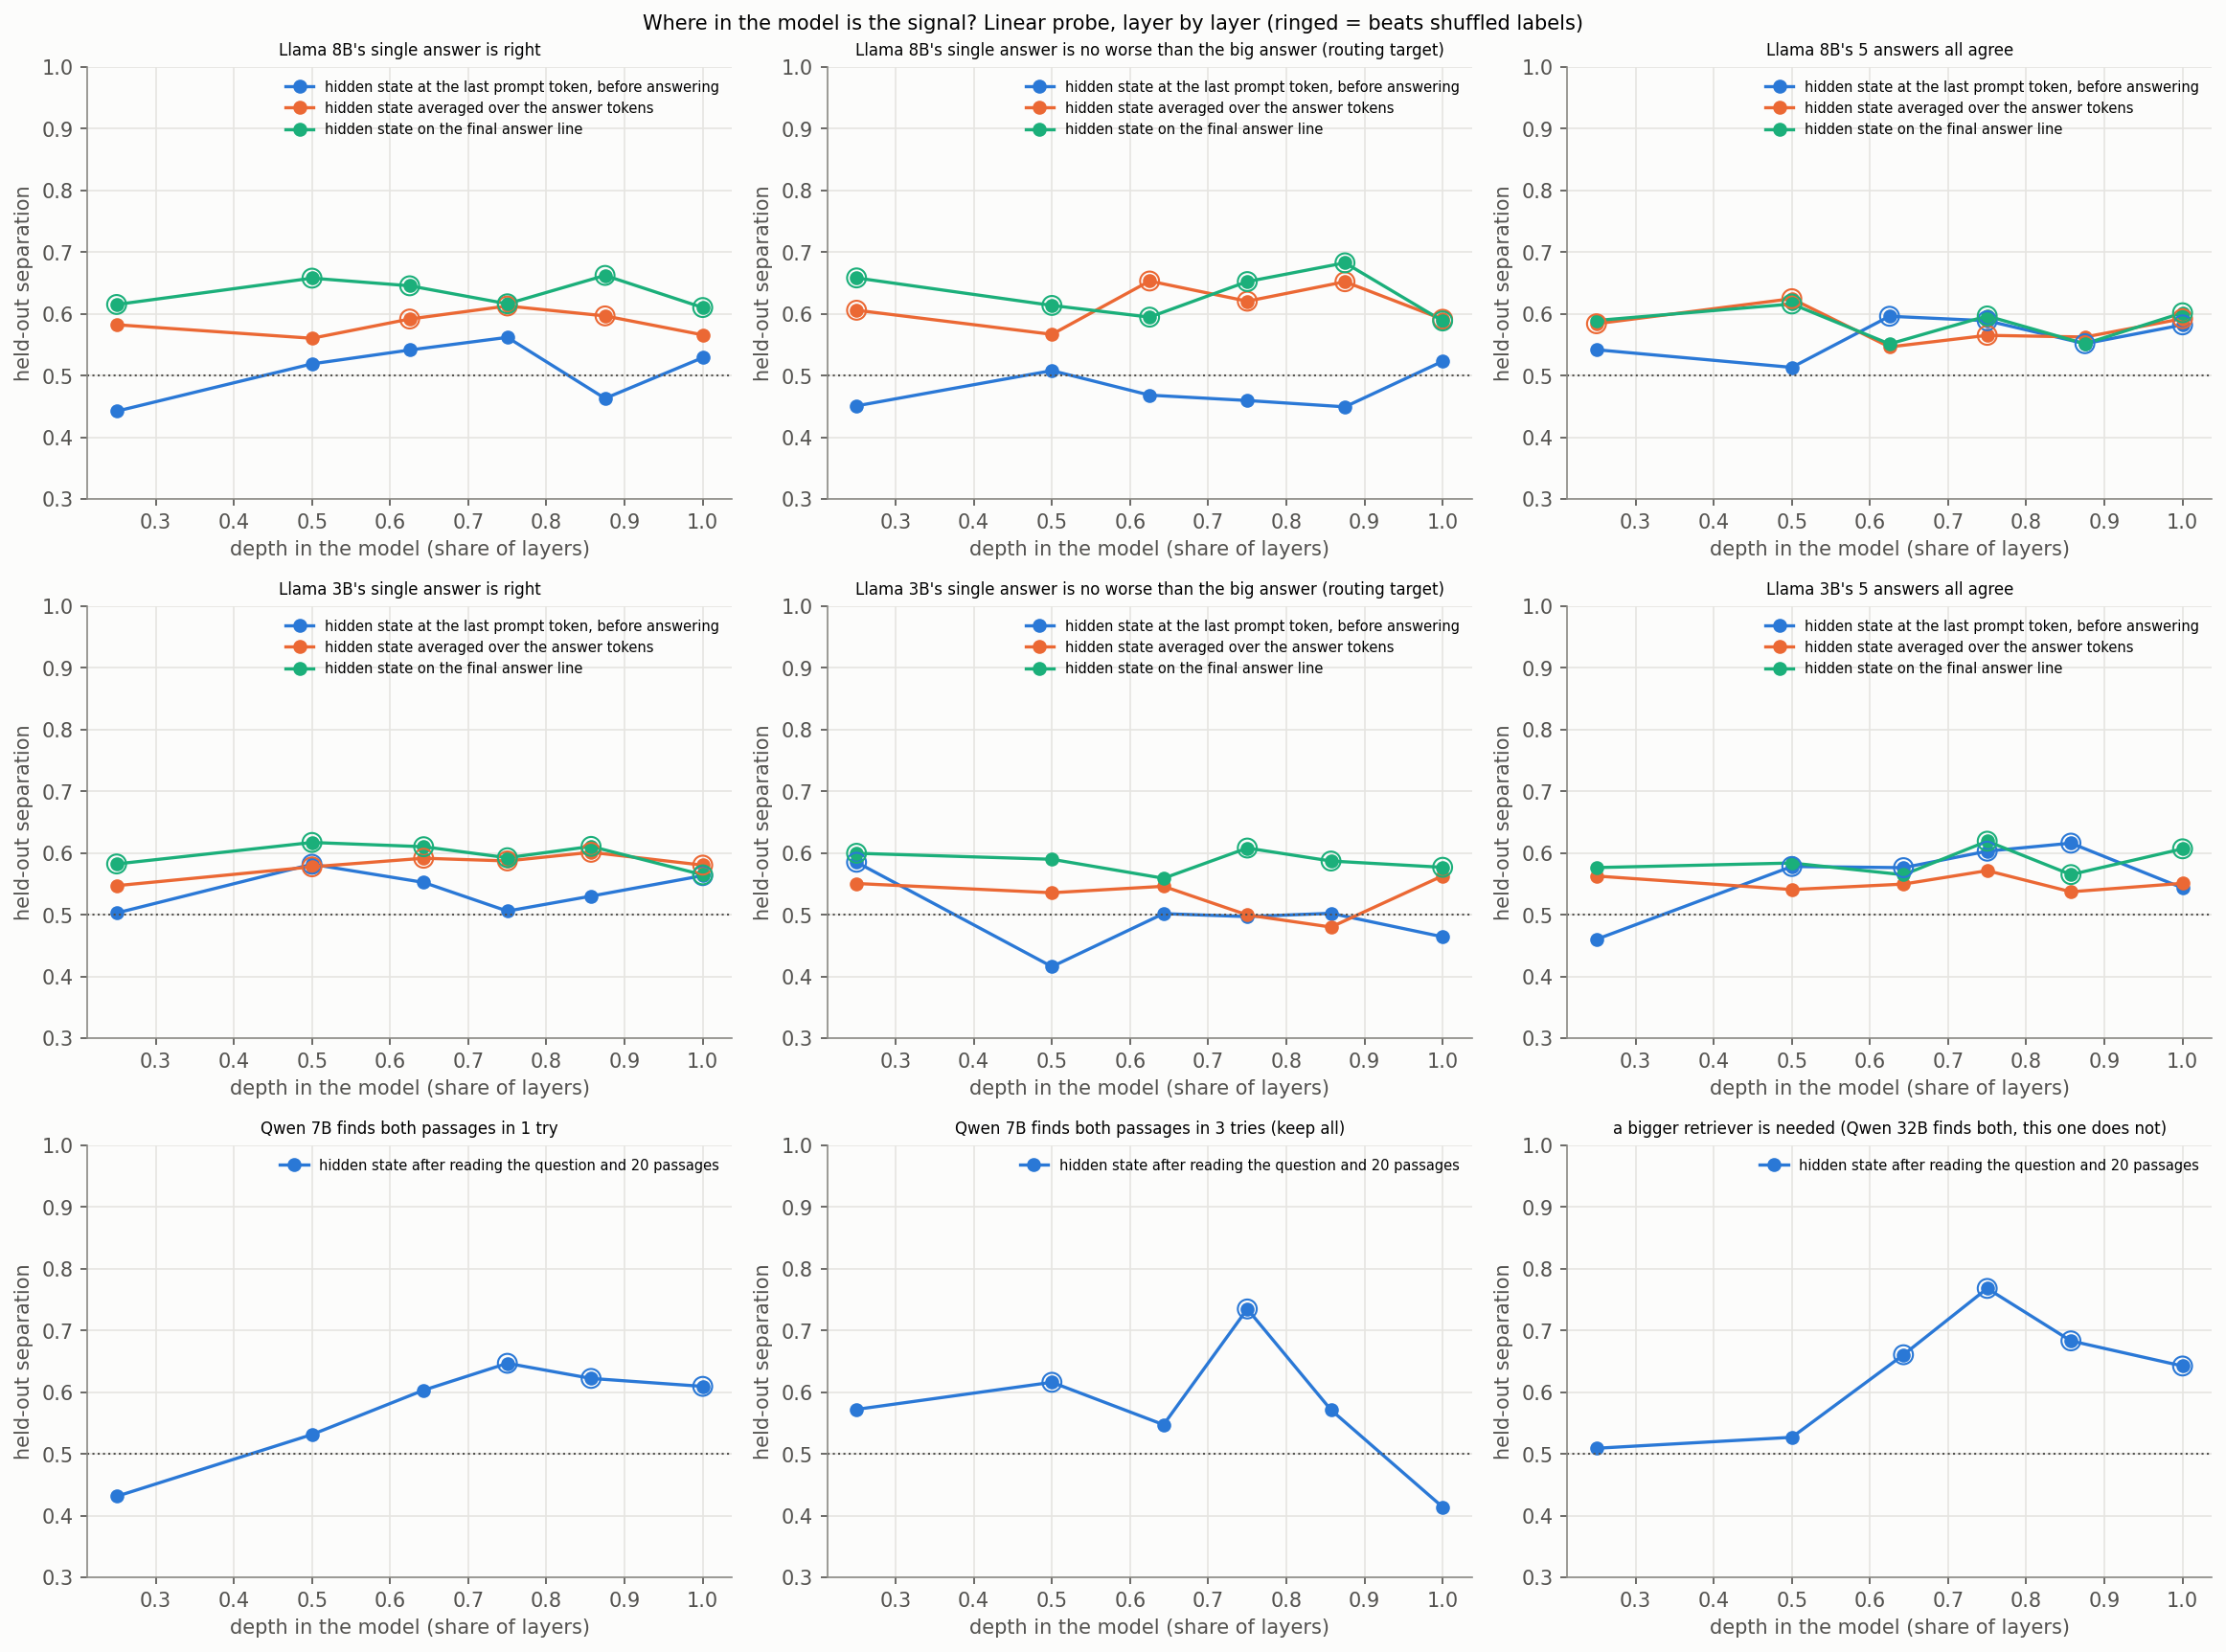

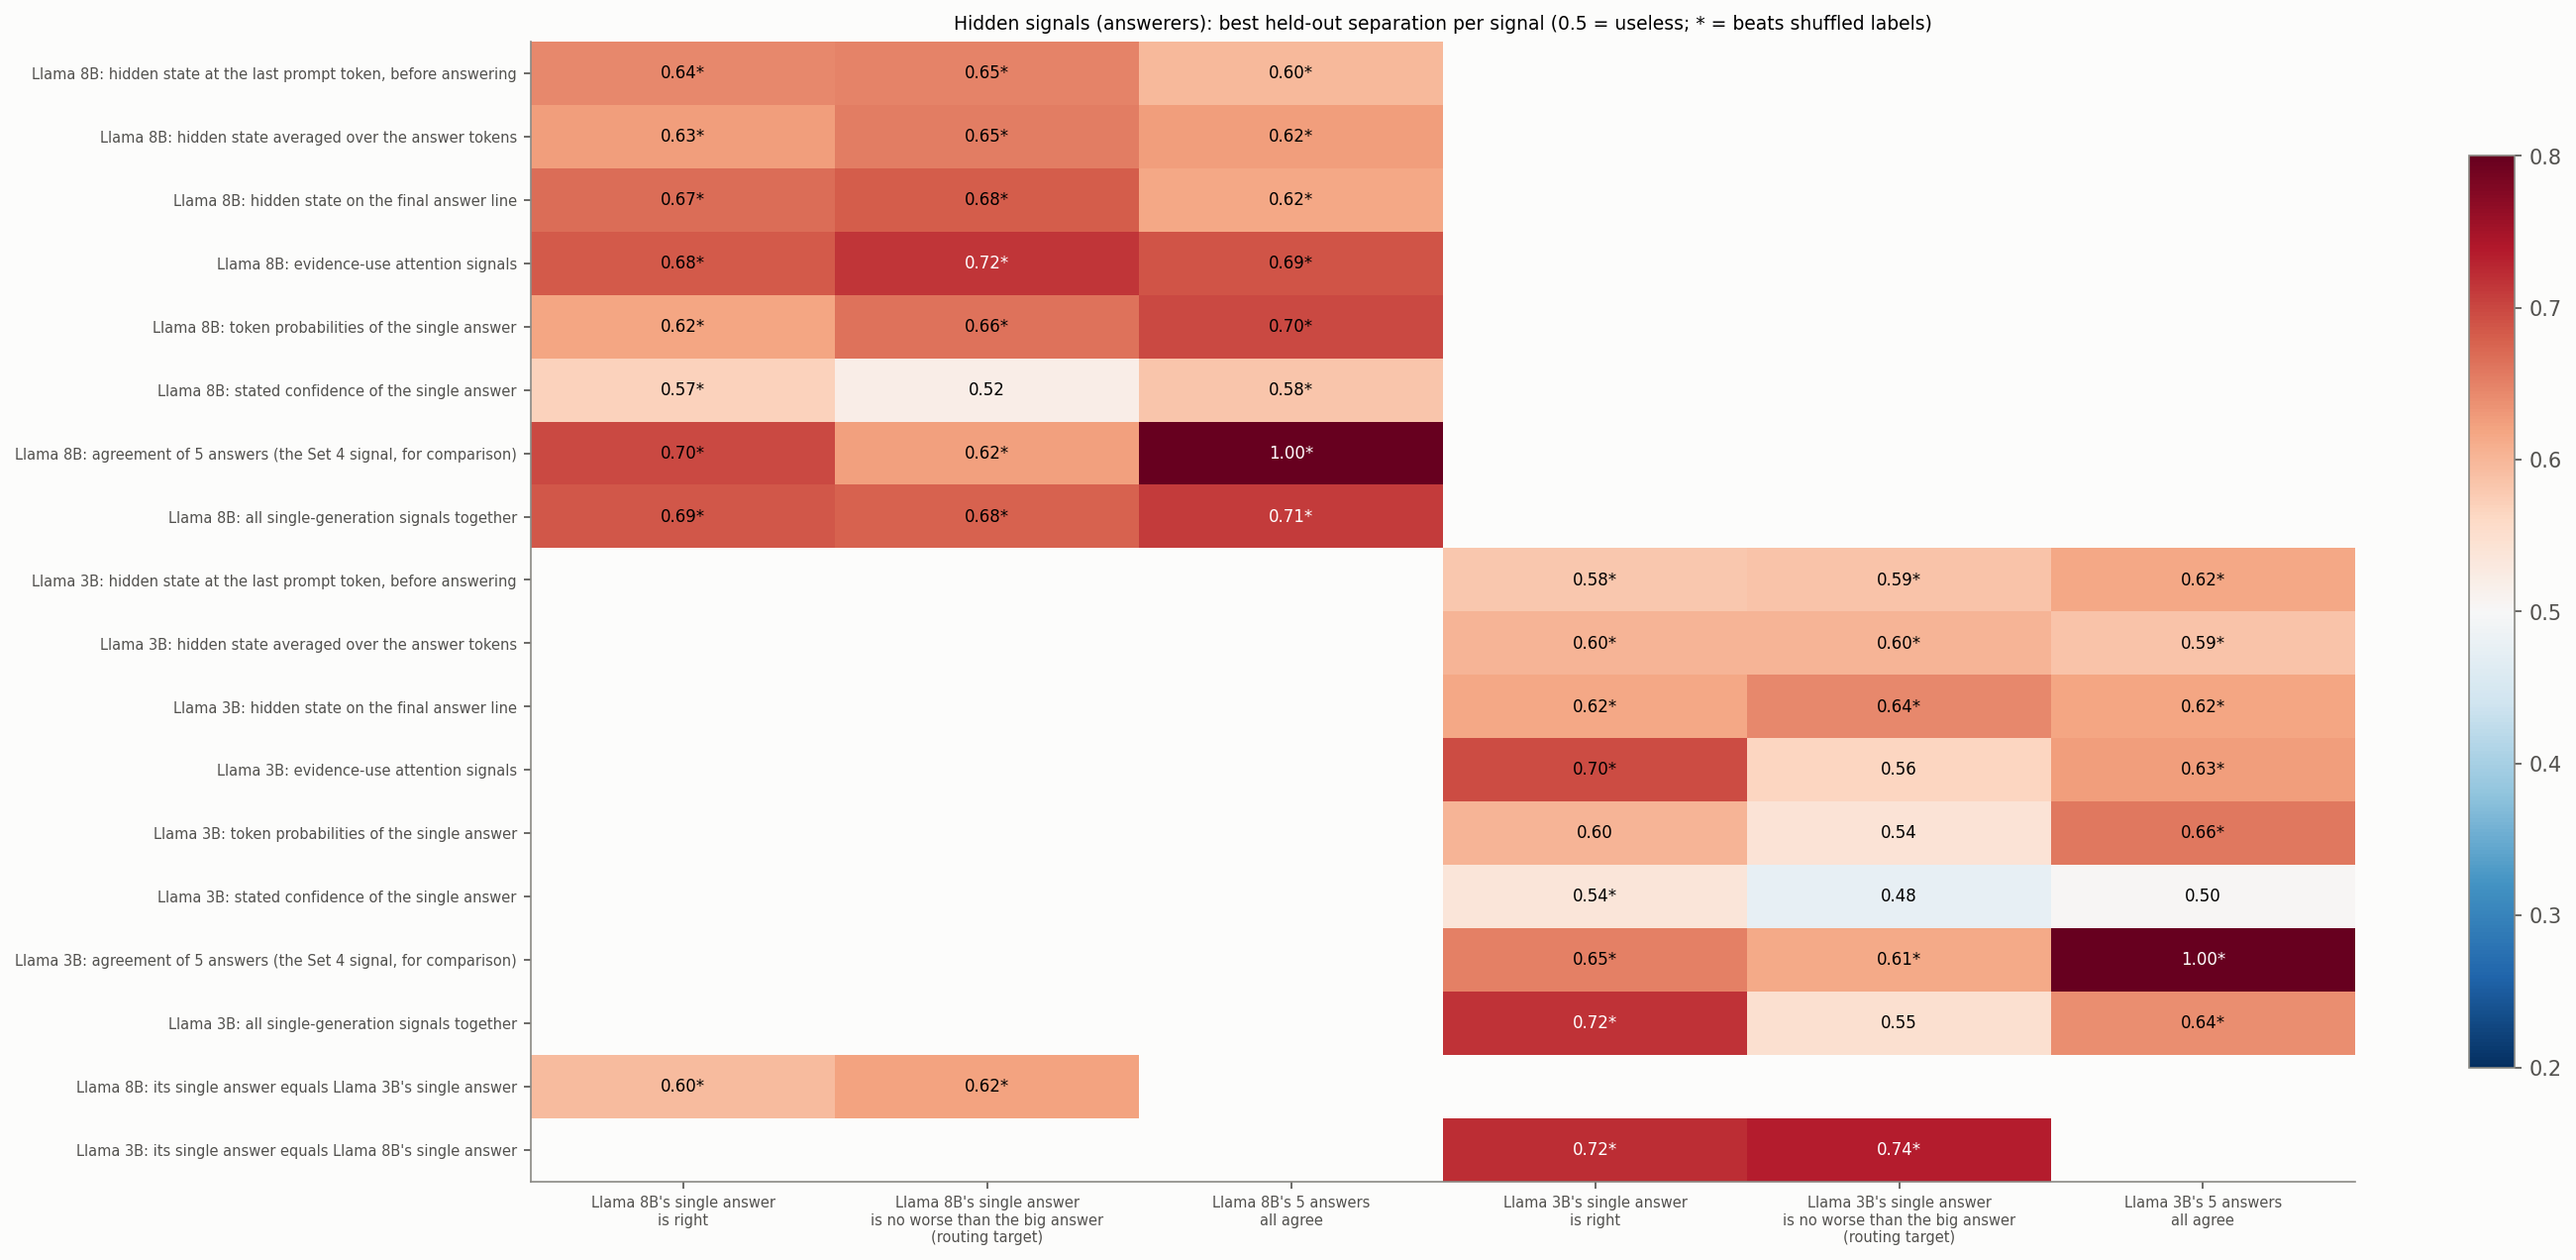

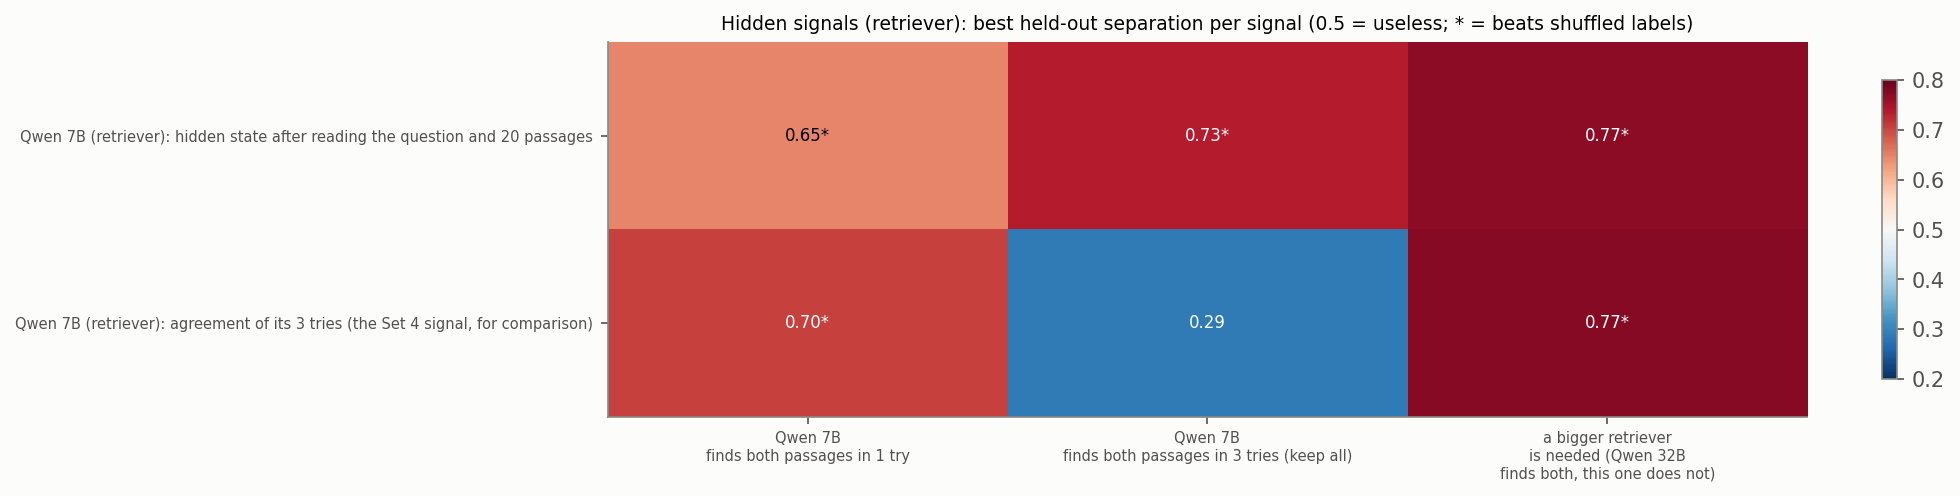

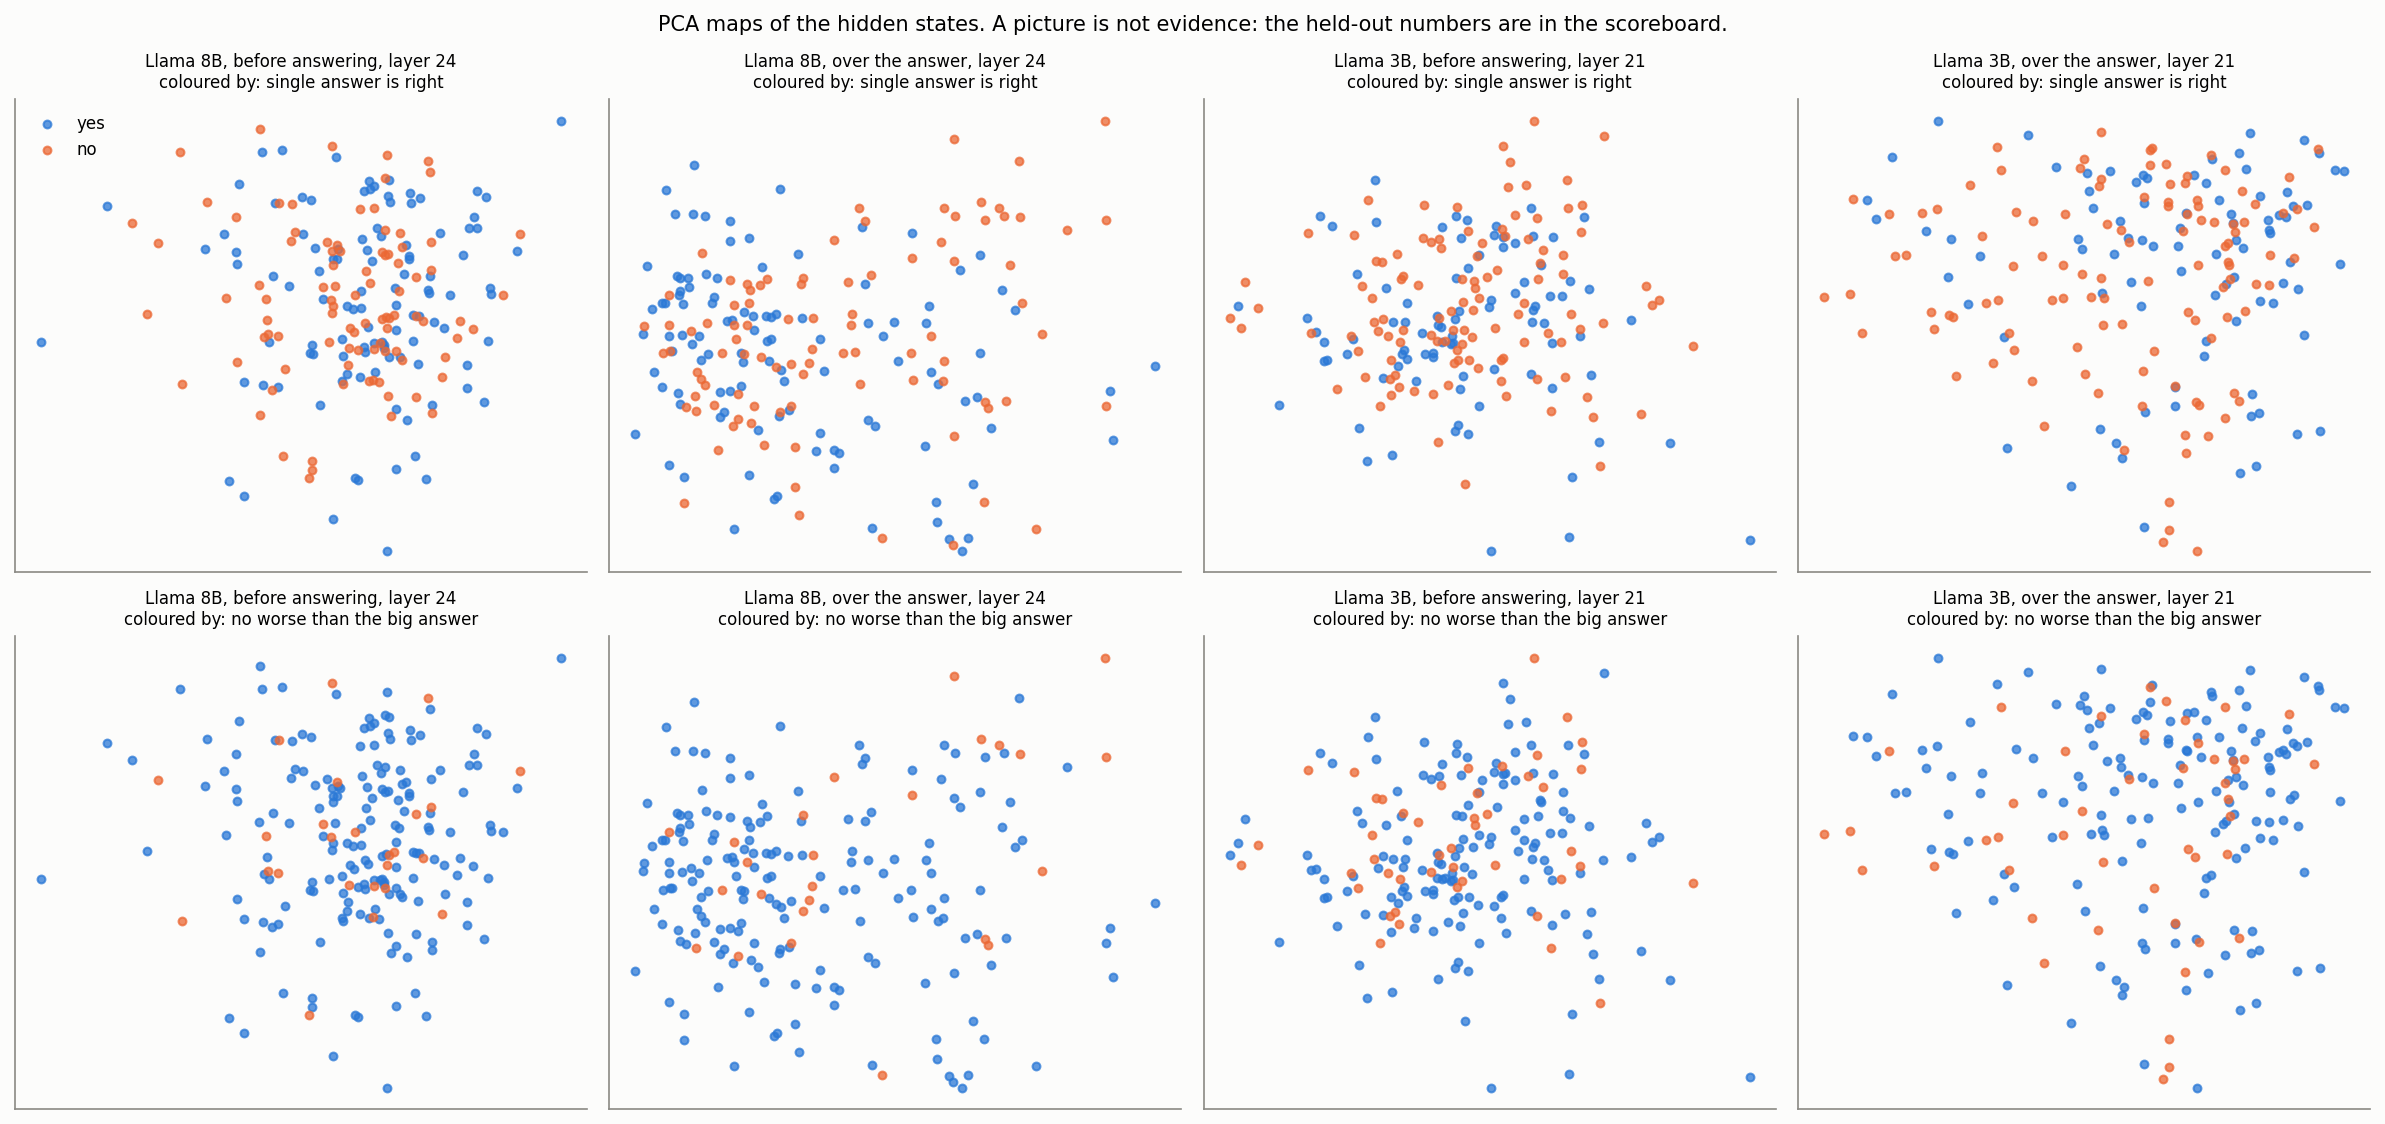

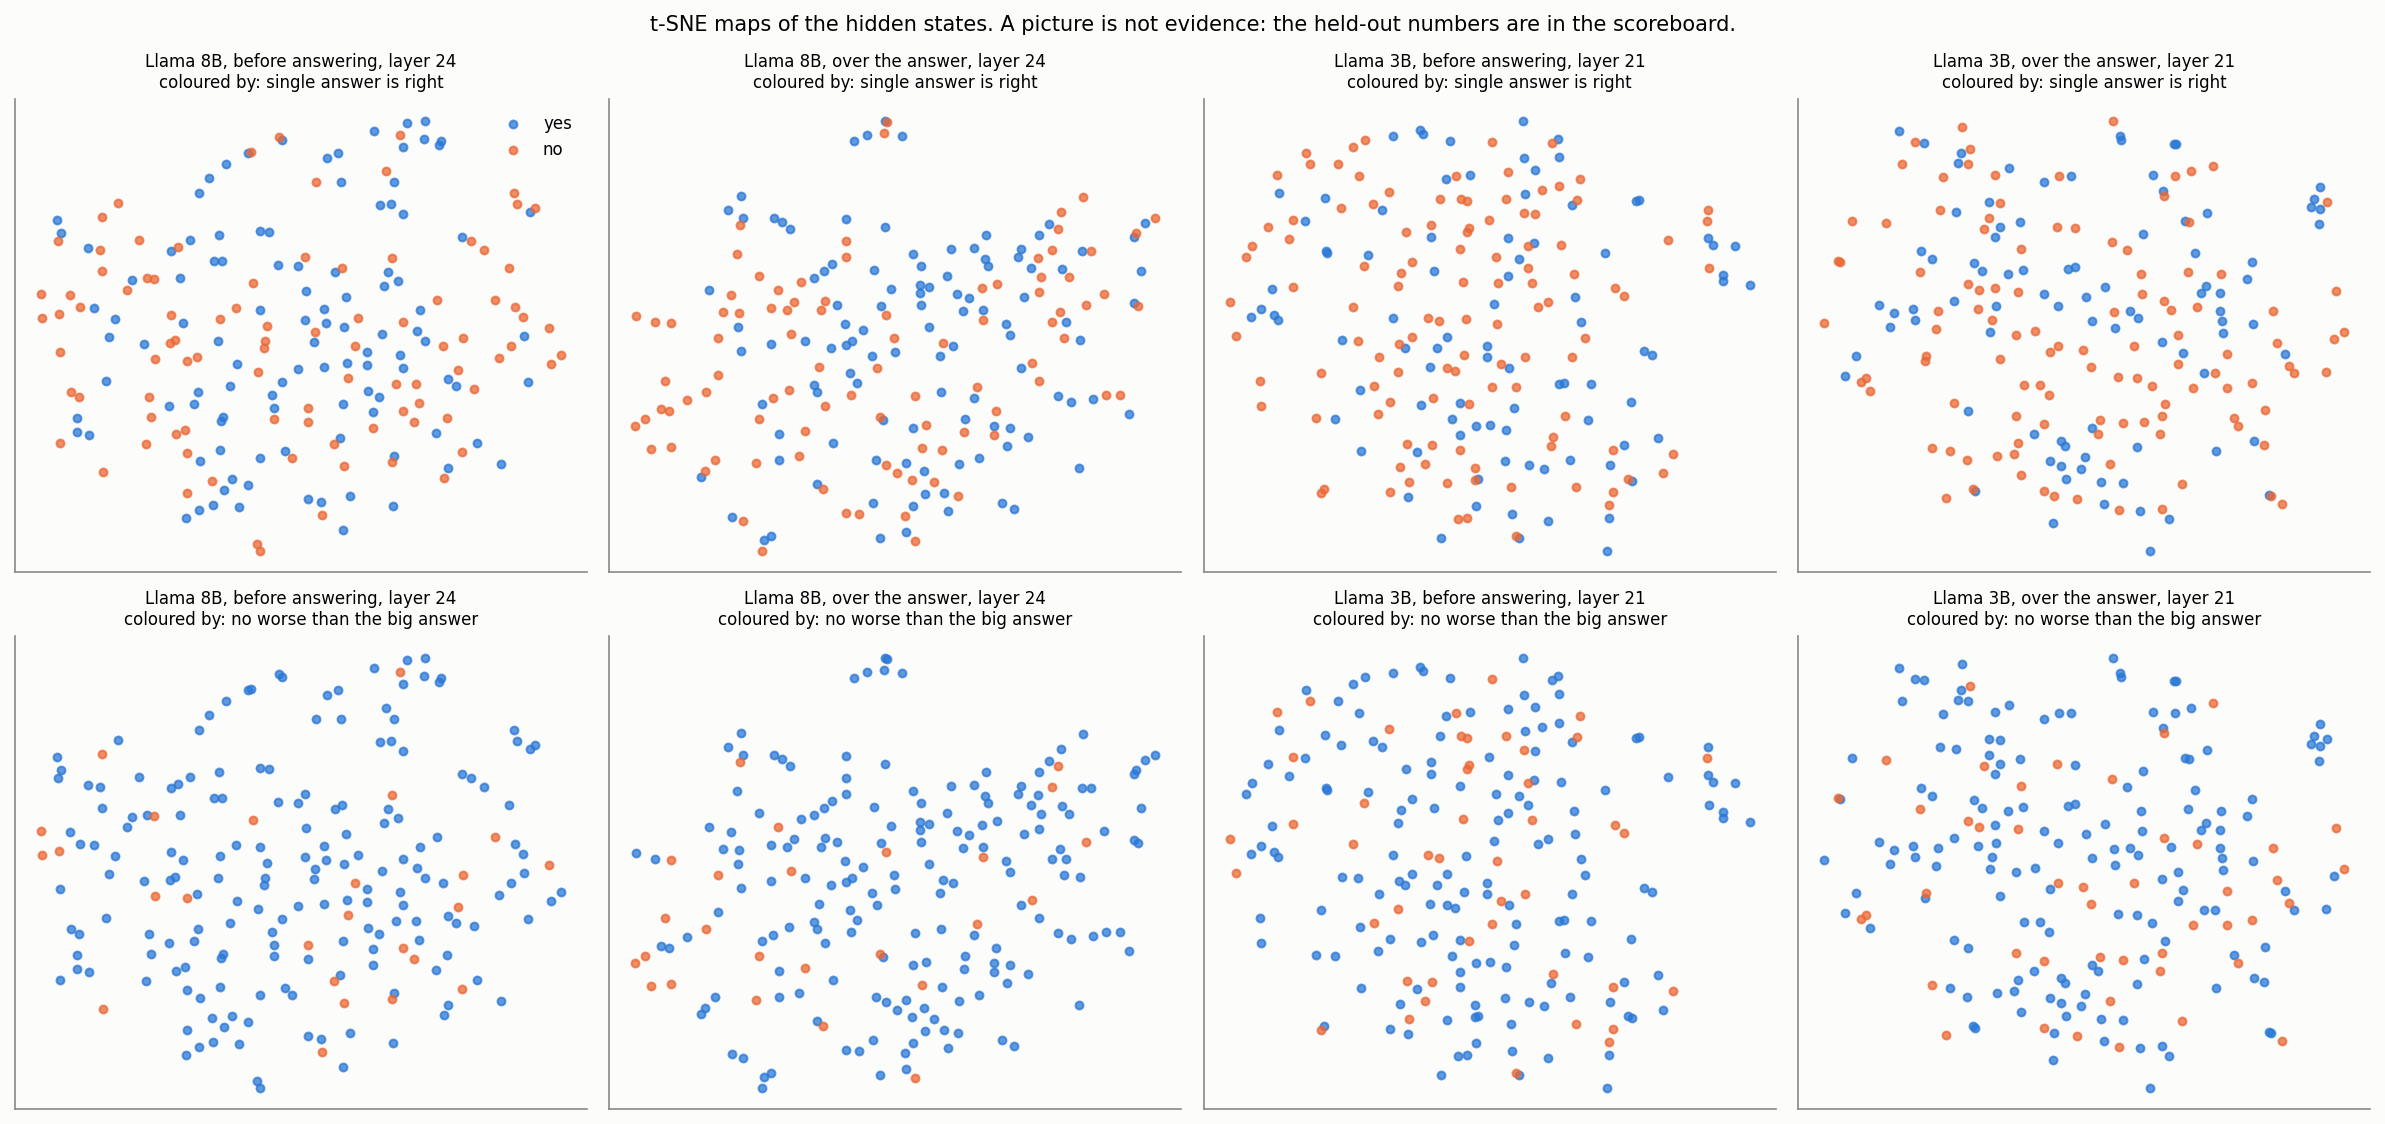

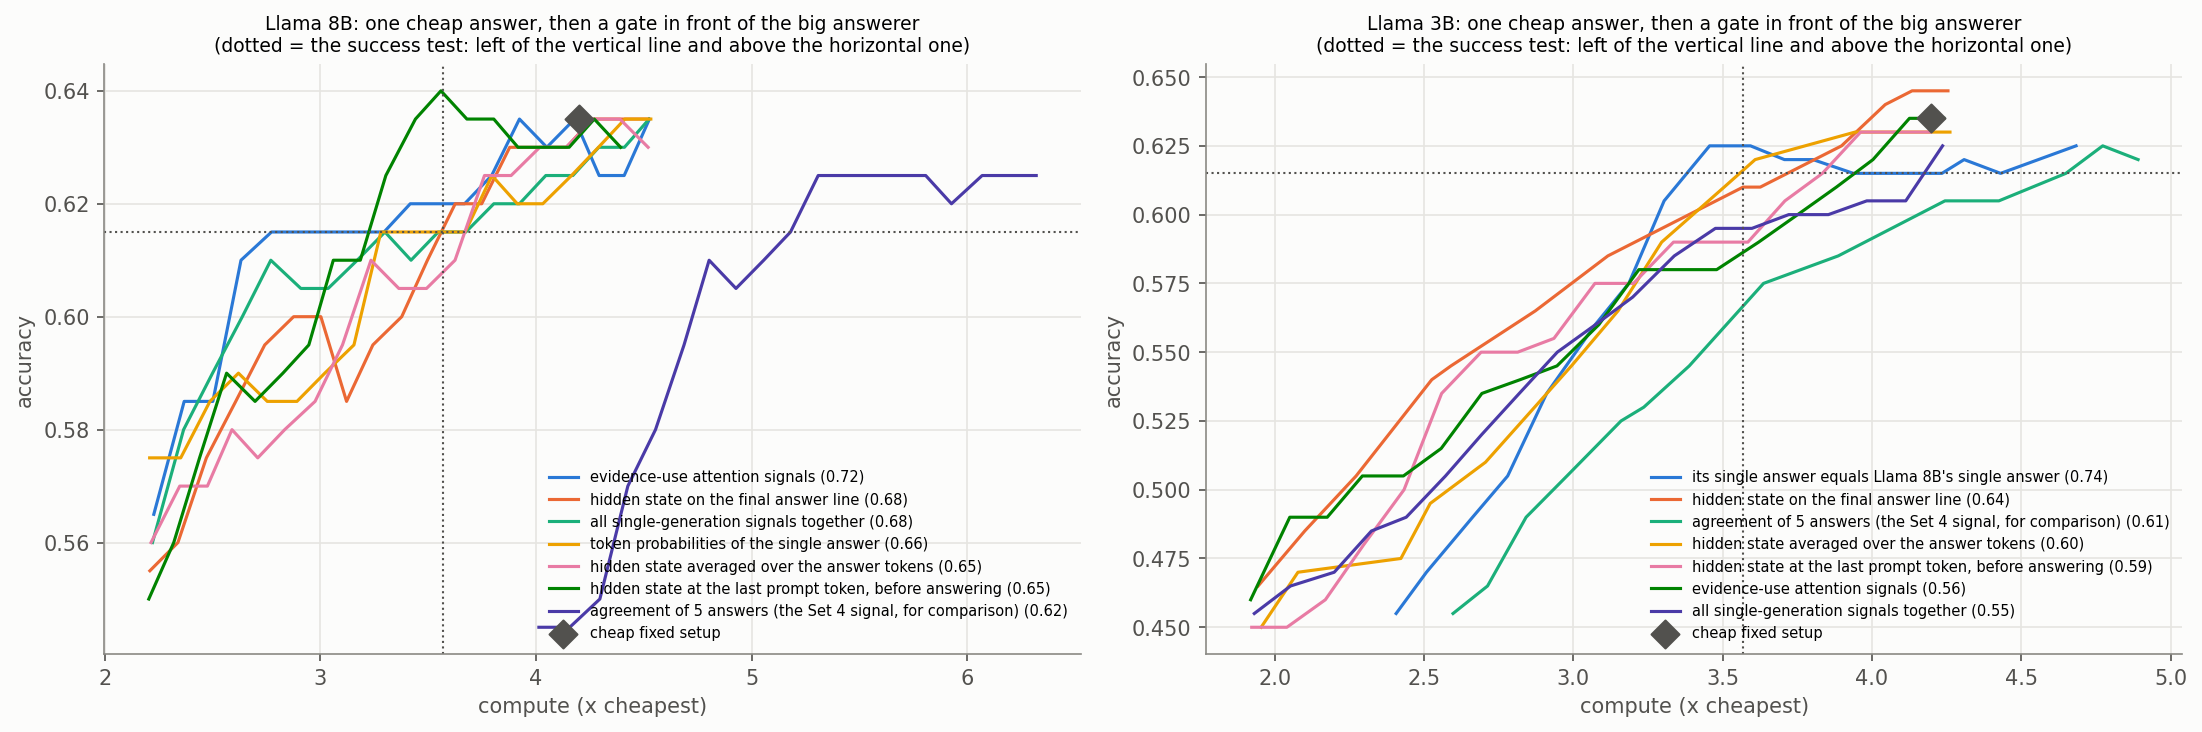

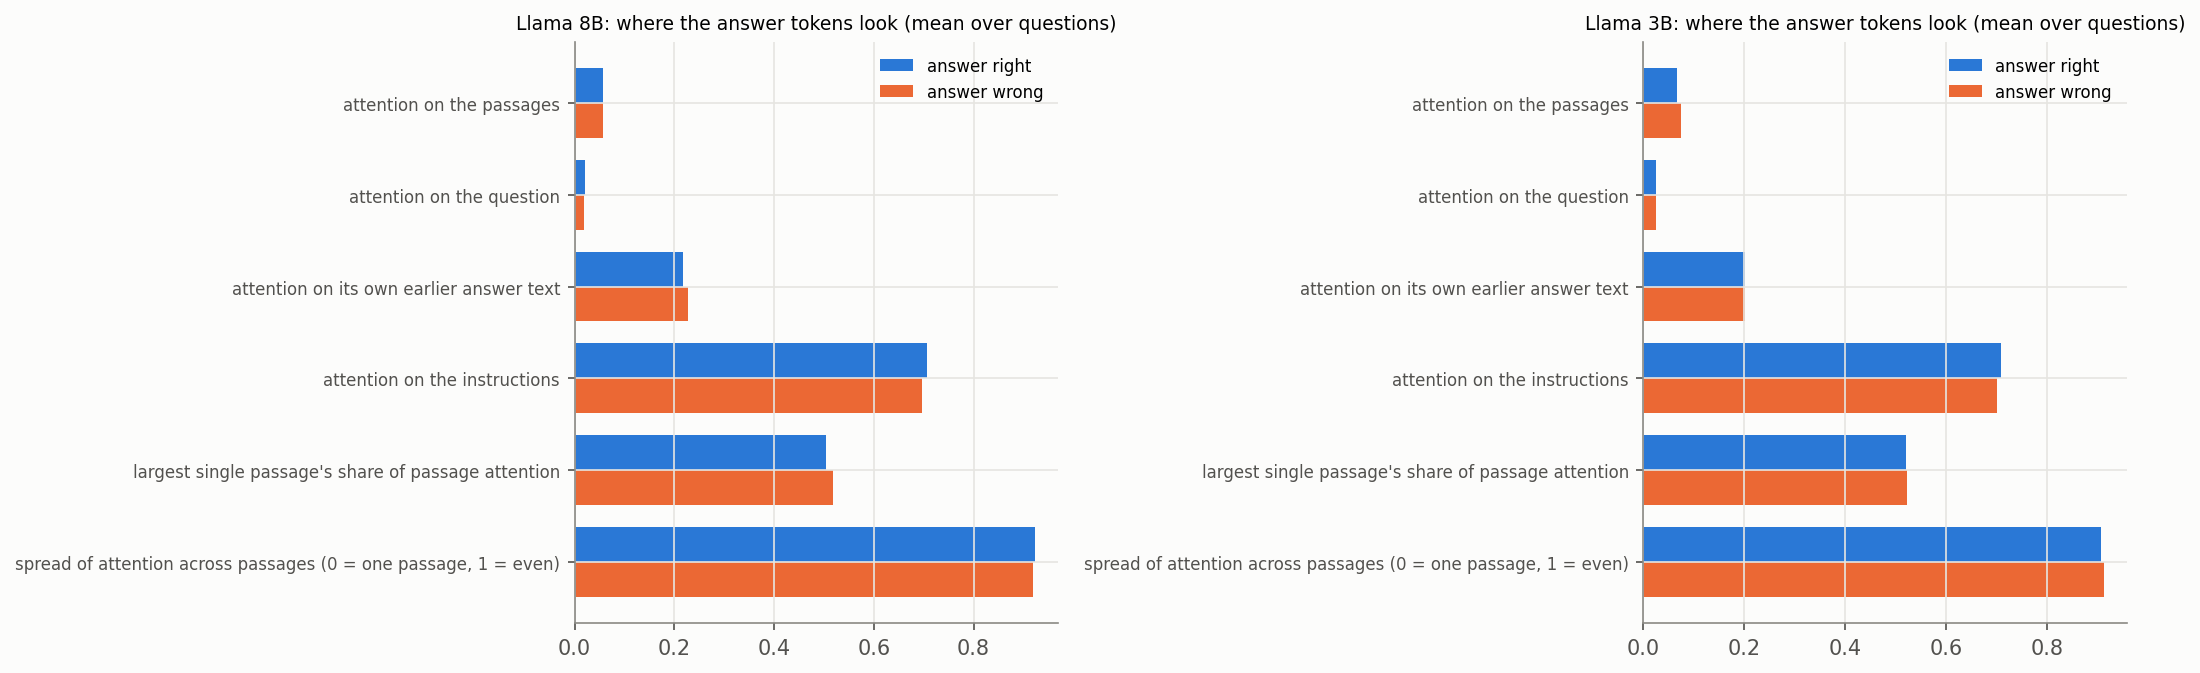

Excel workbook: /content/drive/MyDrive/0_EngD_assignments/0_Small_Big_Model_Switching/runs/Set_2__question-reading-routers/20261007-075955_A100_hidden/results/set5d_hidden.xlsx
Signals for the rule-writing stage: /content/drive/MyDrive/0_EngD_assignments/0_Small_Big_Model_Switching/runs/Set_2__question-reading-routers/20261007-075955_A100_hidden/results/signals_for_rules.jsonl
Wall-clock this session (s): {'extract_answer_l3': 1239, 'copy_q7': 401, 'extract_retrieve_q7': 69, 'analyze': 654, 'total_session': 2374}

ALL DONE.
Saved to Drive.


In [14]:
have = [k for k in ANSWERERS if os.path.exists(f"{RUN_DIR}/step/hidden_answer_{k}.jsonl")]
if have:
    run_stage(["analyze", "--answerers", *have, "--retriever", RETRIEVER, "--repeats", 1 if DRY_RUN else REPEATS,
               "--permutations", 3 if DRY_RUN else PERMUTATIONS] + (["--quick"] if DRY_RUN else []) + COMMON, "analyze.log")
    from IPython.display import Image, Markdown, display
    display(Markdown(open(f"{RUN_DIR}/results/summary.md").read()))
    for f in sorted(glob.glob(f"{RUN_DIR}/results/charts/*.png")):
        display(Image(f))
    os.makedirs(f"{SESSION_DIR}/results_snapshot", exist_ok=True)
    for f in ("summary.md", "set5d_hidden.xlsx", "scoreboard.jsonl", "signals_for_rules.jsonl"):
        shutil.copy(f"{RUN_DIR}/results/{f}", f"{SESSION_DIR}/results_snapshot/{f}")
    shutil.copytree(f"{RUN_DIR}/results/charts", f"{SESSION_DIR}/results_snapshot/charts", dirs_exist_ok=True)
    print("Excel workbook:", f"{RUN_DIR}/results/set5d_hidden.xlsx")
    print("Signals for the rule-writing stage:", f"{RUN_DIR}/results/signals_for_rules.jsonl")
TIMES["total_session"] = round(time.time() - T_START)
json.dump({"session": SESSION, "label": "hidden", "sweep_run": SWEEP_RUN, "run_dir": RUN_DIR, "gpu": gpu, "seconds": TIMES,
           "extraction_complete": ALL_DONE}, open(f"{SESSION_DIR}/session.json", "w"), indent=1)
print("Wall-clock this session (s):", TIMES)
print("\nALL DONE." if ALL_DONE else "\nNOT COMPLETE YET - run this notebook again to continue.")
try:
    drive.flush_and_unmount()
    print("Saved to Drive.")
except Exception as e:
    print("Drive flush skipped:", e)